## Creating stim circuits of the Parity Code

This file shows how the `LhzLegEncoding` class can be used to create stim circuits of the Parity Code. More specifically of the layout of the Parity Code, where the base qubits are layed out along one of the legs of the triangle.

The data qubits and measurment qubits are arranged on a 2d grid with the following coordinates (shown for distance 5 here):

<div style="display: flex; justify-content: space-around;">
    <img src="lattice_layout.png" alt="Lattice Layout" height="400">
</div>

Grey squares represent virtual stabilizers/detectors, which are not included in the stim circuit.

The `LhzLegEncoding` class defines the layout of the data qubits and measurement qubits for different numbers of logical qubits.
It provides a method to create a corresponding *noiseless* syndrome extraction circuit with multiple rounds of measurement. Noise is added separately, by a class from `parity_code.noise_models` (see below).

In [1]:
from parity_code import LhzLegEncoding

num_logical_qubits = 3
rounds = 1
code = LhzLegEncoding(num_logical_qubits=num_logical_qubits)
circuit = code.create_stim_circuit(rounds=rounds)

The circuit can be drawn using stim's `diagram` function

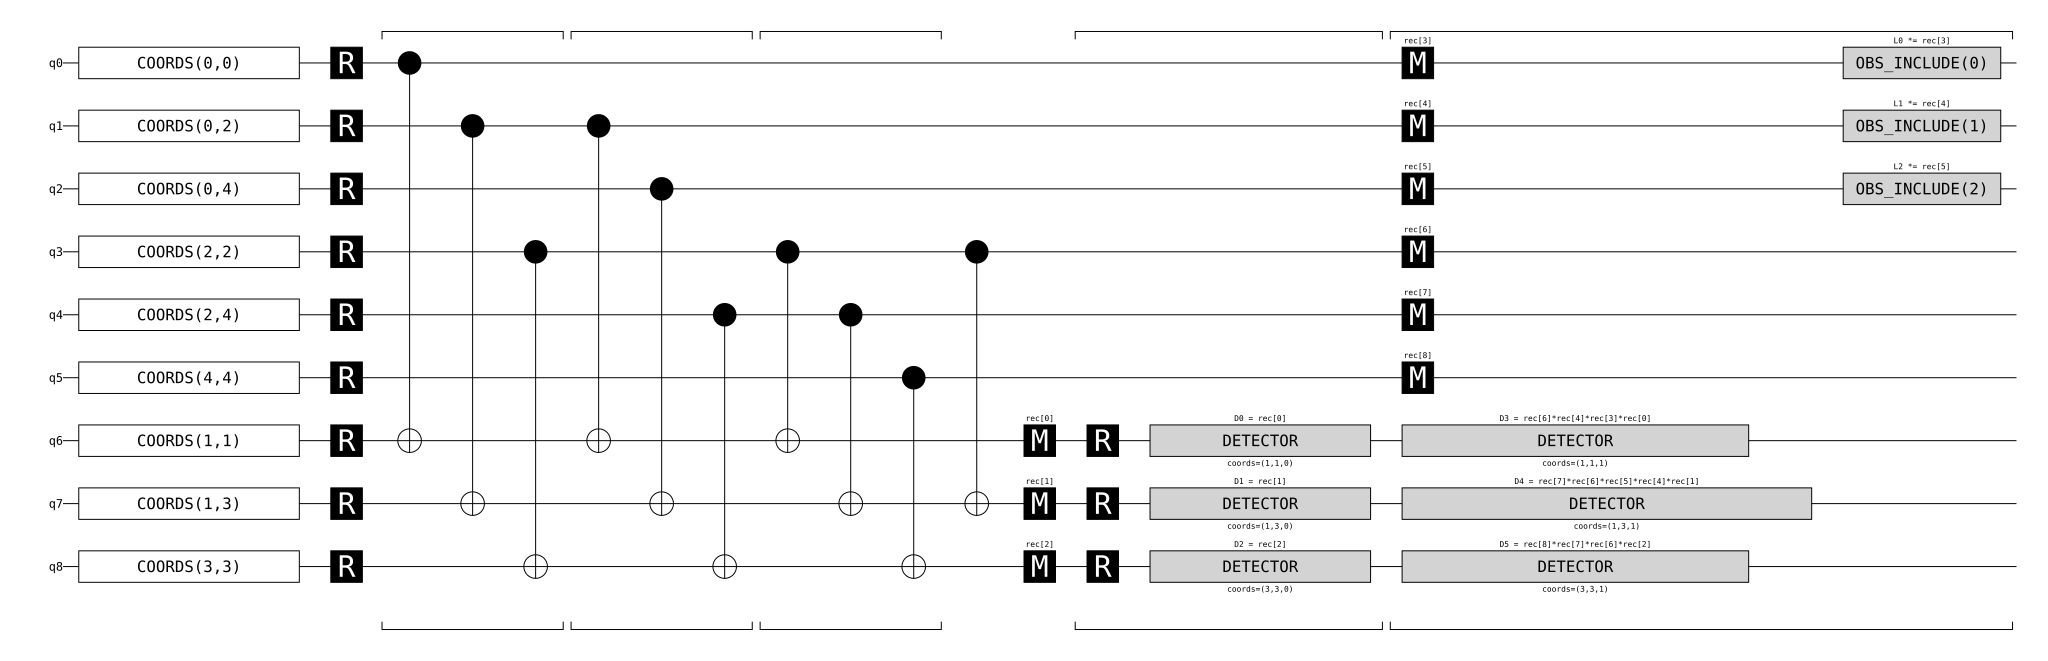

In [2]:
circuit.diagram("timeline-svg")

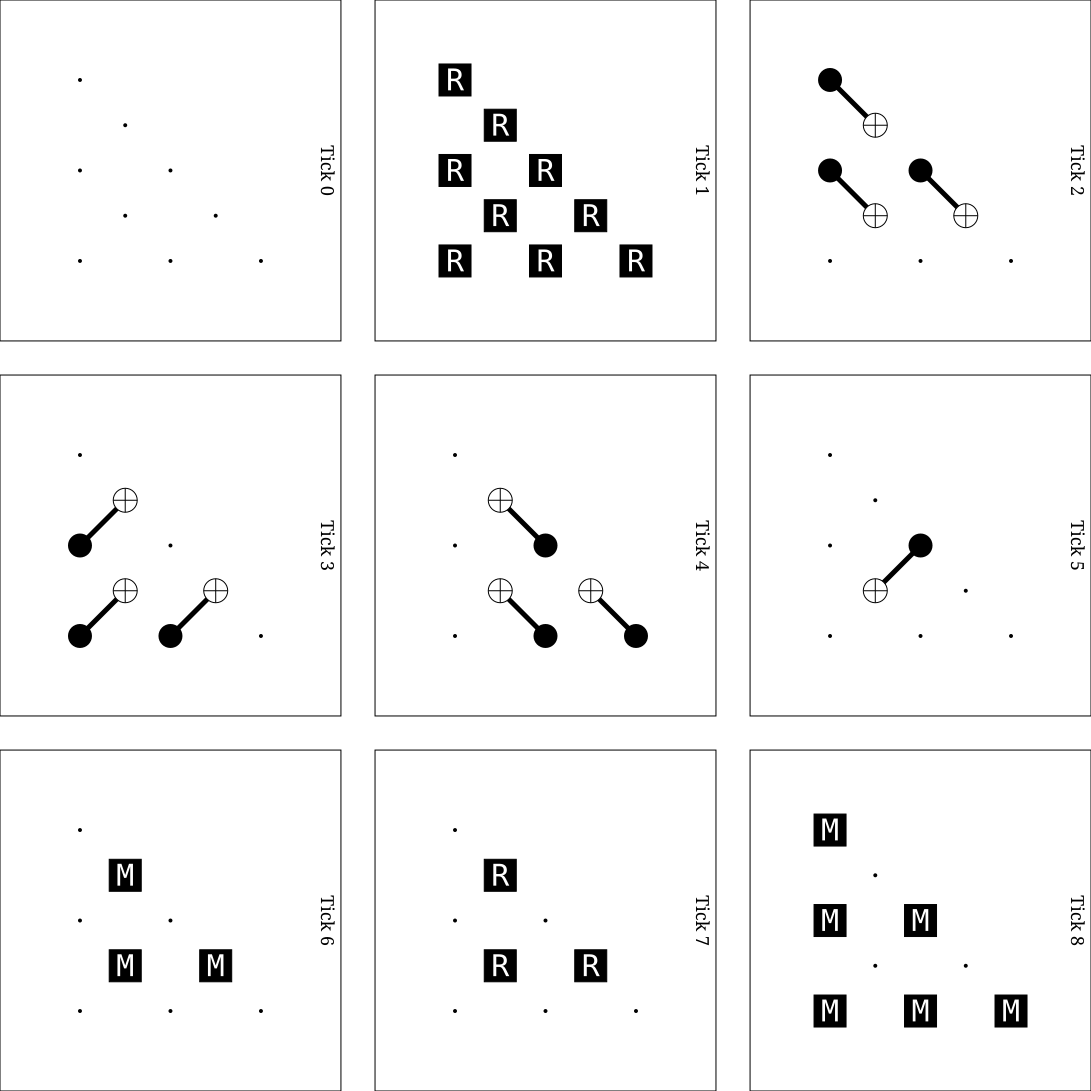

In [3]:
circuit.diagram("timeslice-svg")

## Adding noise

Circuits built by `create_stim_circuit` are noiseless by construction. To get a circuit with a non-trivial detector error model, add noise with a class from `parity_code.noise_models` — for example the generic circuit-level bit-flip model used for the paper's circuit-level-noise simulations:

In [4]:
from parity_code import GenericCircuitLevelNoiseModel

error_probability = 0.01
noise_model = GenericCircuitLevelNoiseModel(
    before_round_bit_flip_prob=error_probability,
    before_measure_flip_prob=error_probability,
    after_reset_flip_prob=error_probability,
    p_2qubits_gate=error_probability,
)
noisy_circuit = noise_model.add_noise_to_circuit(circuit, num_rounds=rounds)

## Detector Error Model

The detector error model can be obtained from the (noisy) stim circuit.

In [5]:
model = noisy_circuit.detector_error_model(approximate_disjoint_errors=True)

In [6]:
# draw the matchgraph corresponding to the detector error model
model.diagram("matchgraph-3d")

{"accessors":[{"bufferView":0,"byteOffset":0,"componentType":5126,"count":9,"max":[0,0.400000005960464,0.400000005960464],"min":[0,-0.400000005960464,-0.400000005960464],"name":"circle_loop","type":"VEC3"},{"bufferView":1,"byteOffset":0,"componentType":5126,"count":9,"max":[0.400000005960464,0,0.400000005960464],"min":[-0.400000005960464,0,-0.400000005960464],"name":"circle_loop","type":"VEC3"},{"bufferView":2,"byteOffset":0,"componentType":5126,"count":9,"max":[0.400000005960464,0.400000005960464,0],"min":[-0.400000005960464,-0.400000005960464,0],"name":"circle_loop","type":"VEC3"},{"bufferView":3,"byteOffset":0,"componentType":5126,"count":9,"max":[0,0.400000005960464,0.400000005960464],"min":[0,-0.400000005960464,-0.400000005960464],"name":"circle_loop","type":"VEC3"},{"bufferView":4,"byteOffset":0,"componentType":5126,"count":9,"max":[0.400000005960464,0,0.400000005960464],"min":[-0.400000005960464,0,-0.400000005960464],"name":"circle_loop","type":"VEC3"},{"bufferView":5,"byteOffset":0,"componentType":5126,"count":9,"max":[0.400000005960464,0.400000005960464,0],"min":[-0.400000005960464,-0.400000005960464,0],"name":"circle_loop","type":"VEC3"},{"bufferView":6,"byteOffset":0,"componentType":5126,"count":16,"max":[15.6666669845581,15.6666669845581,6.33333349227905],"min":[3,3,-3.33333349227905],"name":"buf_scattered_lines","type":"VEC3"},{"bufferView":7,"byteOffset":0,"componentType":5126,"count":14,"max":[3,15.6666669845581,6.33333349227905],"min":[-3.66666698455811,-3.66666698455811,-3.33333349227905],"name":"buf_red_scattered_lines","type":"VEC3"},{"bufferView":8,"byteOffset":0,"componentType":5126,"count":24,"max":[9,9,3],"min":[3,3,0],"name":"buf_blue_scattered_lines","type":"VEC3"}],"asset":{"version":"2.0"},"bufferViews":[{"buffer":0,"byteLength":108,"byteOffset":0,"name":"circle_loop","target":34962},{"buffer":1,"byteLength":108,"byteOffset":0,"name":"circle_loop","target":34962},{"buffer":2,"byteLength":108,"byteOffset":0,"name":"circle_loop","target":34962},{"buffer":3,"byteLength":108,"byteOffset":0,"name":"circle_loop","target":34962},{"buffer":4,"byteLength":108,"byteOffset":0,"name":"circle_loop","target":34962},{"buffer":5,"byteLength":108,"byteOffset":0,"name":"circle_loop","target":34962},{"buffer":6,"byteLength":192,"byteOffset":0,"name":"buf_scattered_lines","target":34962},{"buffer":7,"byteLength":168,"byteOffset":0,"name":"buf_red_scattered_lines","target":34962},{"buffer":8,"byteLength":288,"byteOffset":0,"name":"buf_blue_scattered_lines","target":34962}],"buffers":[{"byteLength":108,"name":"circle_loop","uri":"data:application/octet-stream;base64,AAAAAM3MzD4AAAAAAAAAAMPQkD7D0JA+AAAAAPIwlrLNzMw+AAAAAMPQkL7D0JA+AAAAAM3MzL7yMBazAAAAAMHQkL7E0JC+AAAAAPLkozHNzMy+AAAAAMbQkD6/0JC+AAAAAM3MzD4AAAAA"},{"byteLength":108,"name":"circle_loop","uri":"data:application/octet-stream;base64,AAAAAAAAAADNzMw+w9CQPgAAAADD0JA+zczMPgAAAADyMJayw9CQPgAAAADD0JC+8jAWswAAAADNzMy+xNCQvgAAAADB0JC+zczMvgAAAADy5KMxv9CQvgAAAADG0JA+AAAAAAAAAADNzMw+"},{"byteLength":108,"name":"circle_loop","uri":"data:application/octet-stream;base64,zczMPgAAAAAAAAAAw9CQPsPQkD4AAAAA8jCWss3MzD4AAAAAw9CQvsPQkD4AAAAAzczMvvIwFrMAAAAAwdCQvsTQkL4AAAAA8uSjMc3MzL4AAAAAxtCQPr/QkL4AAAAAzczMPgAAAAAAAAAA"},{"byteLength":108,"name":"circle_loop","uri":"data:application/octet-stream;base64,AAAAAM3MzD4AAAAAAAAAAMPQkD7D0JA+AAAAAPIwlrLNzMw+AAAAAMPQkL7D0JA+AAAAAM3MzL7yMBazAAAAAMHQkL7E0JC+AAAAAPLkozHNzMy+AAAAAMbQkD6/0JC+AAAAAM3MzD4AAAAA"},{"byteLength":108,"name":"circle_loop","uri":"data:application/octet-stream;base64,AAAAAAAAAADNzMw+w9CQPgAAAADD0JA+zczMPgAAAADyMJayw9CQPgAAAADD0JC+8jAWswAAAADNzMy+xNCQvgAAAADB0JC+zczMvgAAAADy5KMxv9CQvgAAAADG0JA+AAAAAAAAAADNzMw+"},{"byteLength":108,"name":"circle_loop","uri":"data:application/octet-stream;base64,zczMPgAAAAAAAAAAw9CQPsPQkD4AAAAA8jCWss3MzD4AAAAAw9CQvsPQkD4AAAAAzczMvvIwFrMAAAAAwdCQvsTQkL4AAAAA8uSjMc3MzL4AAAAAxtCQPr/QkL4AAAAAzczMPgAAAAAAAAAA"},{"byteLength":192,"name":"buf_scattered_lines","uri":"data:application/octet-stream;b